# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** *(The goal of this supervised binary classification task is to predict whether a breast mass is malignant (0) or benign (1) based on 30 numeric features—the mean, standard error, and worst values of 10 cell nucleus characteristics—computed from 569 fine-needle aspirate (FNA) images. Predicting a malignant tumor to be benign (1 instead of 0) is the more costly error because leaving cancer undiagnosed deprives a patient of timely medical intervention. Therefore, model success will be evaluated by achieving high recall on the malignant class (0) to catch as many true cancer cases as possible, alongside high F1-score and ROC-AUC values.)*

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [4]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
...

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [3]:
# TODO: load the dataset and copy its DataFrame into df
data = load_breast_cancer(as_frame=True)
df = data.frame
print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [13]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
print("Shape:", df.shape)
print("\nCounts of each dtype:")
print(df.dtypes.value_counts())

df.head(5)

Shape: (569, 31)

Counts of each dtype:
float64    30
int64       1
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [14]:
# TODO: class counts and percentages
counts = df['target'].value_counts()
proportions = df['target'].value_counts(normalize=True)

class_summary = pd.DataFrame({
    'Count': counts,
    'Proportion': proportions,
    'Percentage (%)': (proportions * 100).round(2)
})
print(class_summary)

        Count  Proportion  Percentage (%)
target                                   
1         357    0.627417           62.74
0         212    0.372583           37.26


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [15]:
# TODO: describe().T, then the 10 largest skewness values
display(df.describe().T)

print("\n10 Most Skewed Features:")
feature_cols = df.drop(columns='target')
print(feature_cols.skew().sort_values(ascending=False).head(10))

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



10 Most Skewed Features:
area error                 5.447186
concavity error            5.110463
fractal dimension error    3.923969
perimeter error            3.443615
radius error               3.088612
smoothness error           2.314450
symmetry error             2.195133
compactness error          1.902221
worst area                 1.859373
worst fractal dimension    1.662579
dtype: float64


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [16]:
# TODO: correlation with target, sorted
corr_with_target = df.corr()['target'].drop('target').sort_values()

print("5 Most Negative Correlations with Target:")
print(corr_with_target.head(5))

print("\n5 Most Positive Correlations with Target:")
print(corr_with_target.tail(5))

5 Most Negative Correlations with Target:
worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
Name: target, dtype: float64

5 Most Positive Correlations with Target:
fractal dimension error   -0.077972
symmetry error             0.006522
texture error              0.008303
mean fractal dimension     0.012838
smoothness error           0.067016
Name: target, dtype: float64


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** *(This is a supervised binary classification problem to predict whether a breast mass is malignant (0) or benign (1) using 30 numeric cell nucleus measurements from 569 FNA images. Predicting benign (1) for a truly malignant (0) mass is the more costly error because it leaves cancer undiagnosed and delays urgent treatment. Success will be judged by maximizing recall for the malignant class (0), supported by high F1-score and ROC-AUC values.)*

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

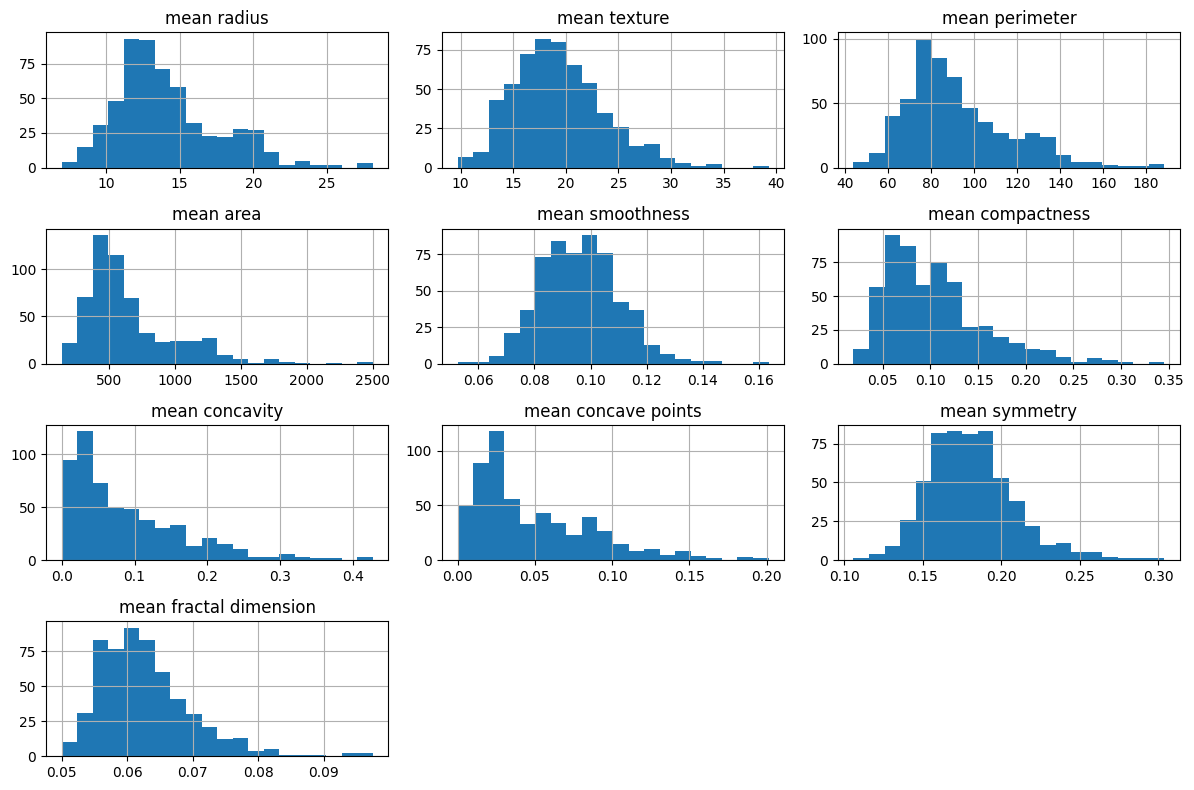

In [17]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)
df.filter(like="mean").hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

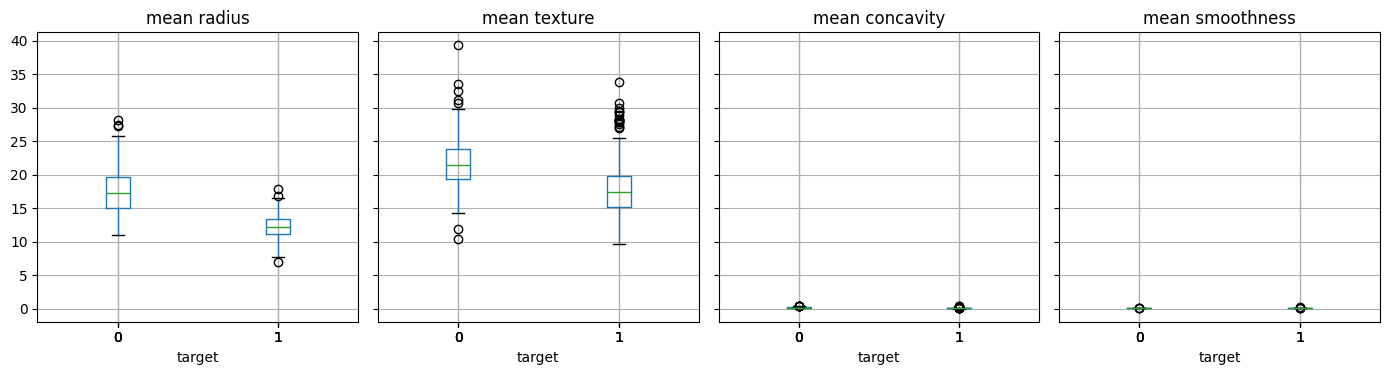

In [18]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
df.boxplot(column=features, by="target", layout=(1, 4), figsize=(14, 4))
plt.suptitle("")
plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

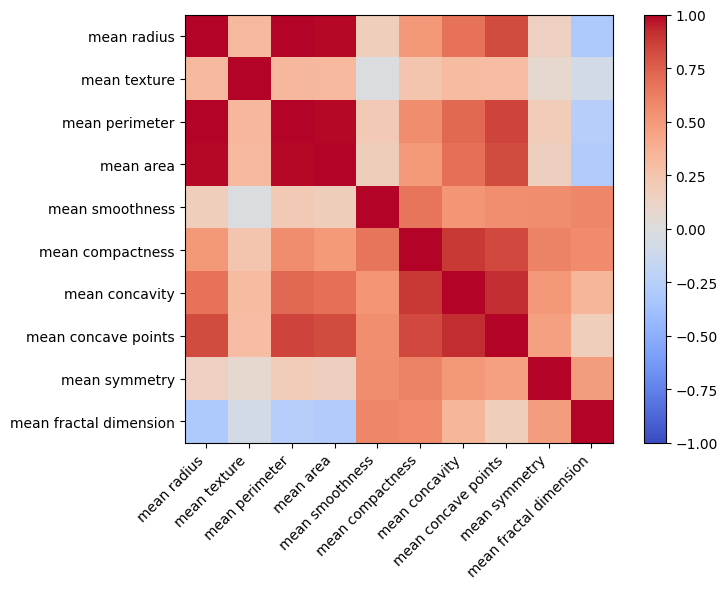

In [19]:
# TODO: correlation matrix of the "mean" features drawn with imshow
corr_mean = df.filter(like="mean").corr()
plt.figure(figsize=(8, 6))
plt.imshow(corr_mean, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr_mean)), corr_mean.columns, rotation=45, ha="right")
plt.yticks(range(len(corr_mean)), corr_mean.columns)
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

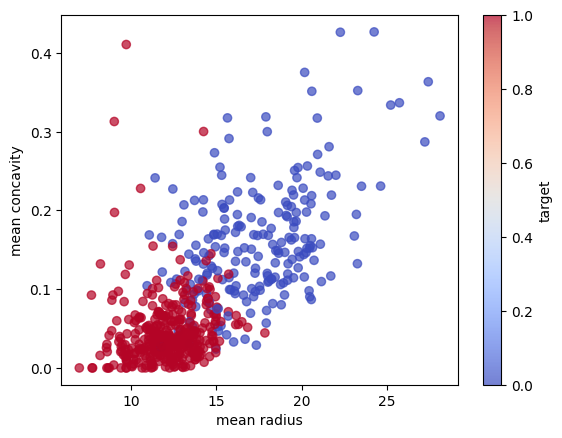

In [20]:
# TODO: coloured scatter plot with axis labels and a colourbar
plt.scatter(df["mean radius"], df["mean concavity"], c=df["target"], cmap="coolwarm", alpha=0.7)
plt.xlabel("mean radius")
plt.ylabel("mean concavity")
plt.colorbar(label="target")
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:** *(Redundant features: mean radius, mean perimeter, and mean area are nearly perfectly correlated because perimeter and area are direct geometric functions of radius; similarly, mean concavity, mean concave points, and mean compactness are strongly correlated with one another.
Best class separation: Among the plotted features, mean radius and mean concavity (along with mean concave points, mean perimeter, and mean area) separate the malignant (0) and benign (1) classes most clearly, showing minimal interquartile overlap in the box plots and distinct clusters in the scatter plot.)*

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [22]:
# TODO: total missing values and duplicated rows
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

X = df.drop(columns="target")
y = df["target"]

Missing values: 0
Duplicate rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [23]:
# TODO: IQR outlier count per feature
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outliers = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()
print(outliers.nlargest(10))

area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
compactness error          28
fractal dimension error    28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** *(No. In this medical dataset, extreme values (such as very large area, radius, or concavity) represent real pathological characteristics of aggressive malignant tumors (0) rather than data entry errors. Deleting outlying rows from a small dataset (569 instances) would throw away vital training examples and disproportionately remove the minority malignant class; instead, we should keep them and handle skewness using power/log transforms (PowerTransformer) or RobustScaler.)*

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [ ]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95
...

**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [ ]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores
...

**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [ ]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features
...

**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

In [ ]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10
...

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [ ]:
# TODO: vote across the three methods
...

> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [ ]:
# TODO: train_test_split with stratify=y
...
print(X_train.shape, X_test.shape)

**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [ ]:
# TODO: fit both scalers on X_train and print the verifying statistics
...

**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [ ]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance
...

---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM
models = {
    "LR": LogisticRegression(max_iter=5000, random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC(random_state=seed)
}


def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [31]:
# To fix the NameError, we make sure the train_test_split is performed first
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=7)

# Now we can safely call spot_check twice
raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

summary = pd.DataFrame({
    "raw": pd.DataFrame(raw_results).mean(),
    "scaled": pd.DataFrame(scaled_results).mean()
})
display(summary.round(4))

,raw,scaled
LR,0.9538,0.9823
LDA,0.9472,0.9472
KNN,0.9229,0.9649
CART,0.9276,0.9276
NB,0.9341,0.9320
SVM,0.8987,0.9758


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** *(double-click to edit)*

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [ ]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
...

**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

In [ ]:
# TODO: box plot of the 10 fold scores per model
...

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [ ]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
...

---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [ ]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]
...

**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [ ]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]
...

### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [ ]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
...

**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [ ]:
# TODO: leaderboard Series
...

### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

In [ ]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix
...

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [ ]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
...

---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.